# 07 — Kepler false-positive and false-negative analysis



## 1. Refit on each training fold and predict only held-out validation observations

Each training observation receives one out-of-fold prediction per model. All three models use the same folds. The XGBoost parameters are taken from the previous tuning notebook.

In [2]:

import os
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '1'

import warnings
from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    confusion_matrix, f1_score, precision_score,
    recall_score, accuracy_score, roc_auc_score
)
from sklearn.exceptions import ConvergenceWarning
from xgboost import XGBClassifier

warnings.filterwarnings('ignore', category=ConvergenceWarning)

ROOT = Path(".")
DATA_DIR = ROOT / "Kepler_Datasets"

def load_csv(filename):
    path = DATA_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f"File not found: {path.resolve()}")
    return pd.read_csv(path)

X = load_csv("X_train.csv")
y = load_csv("y_train.csv")["target"].astype(int).to_numpy()
ids = load_csv("train_ids.csv")

groups = ids["kepid"].to_numpy()

assert len(X) == len(y) == len(ids)
assert X.shape[1] == 19
assert {"kepid", "kepoi_name"}.issubset(ids.columns)

folds = list(
    StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ).split(X, y, groups)
)

print("Training observations:", len(X))
print("Features:", X.shape[1])
print("CV folds:", len(folds))

def build_model(name):
    if name == "Decision Tree":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("tree", DecisionTreeClassifier(
                criterion="gini",
                max_depth=8,
                min_samples_split=10,
                min_samples_leaf=10,
                class_weight="balanced",
                random_state=42
            ))
        ])

    if name == "Optimized MLP":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("mlp", MLPClassifier(
                hidden_layer_sizes=(64, 32),
                activation="relu",
                solver="adam",
                alpha=0.01,
                learning_rate_init=0.001,
                batch_size=128,
                max_iter=90,
                n_iter_no_change=20,
                tol=1e-4,
                early_stopping=False,
                random_state=42
            ))
        ])

    if name == "Tuned XGBoost":
        return XGBClassifier(
            n_estimators=600, max_depth=8, learning_rate=0.05,
            reg_lambda=1, reg_alpha=0, min_child_weight=5,
            subsample=0.8, colsample_bytree=0.8, scale_pos_weight=1.0,
            objective="binary:logistic", eval_metric="logloss",
            tree_method="hist", max_bin=64, random_state=42, n_jobs=1
        )

    raise ValueError(f"Unknown model: {name}")

rows = []
metrics = []

for name in ["Decision Tree", "Optimized MLP", "Tuned XGBoost"]:
    for k, (tr, va) in enumerate(folds, 1):
        model = build_model(name)
        model.fit(X.iloc[tr], y[tr])

        predictions = model.predict(X.iloc[va])
        probabilities = model.predict_proba(X.iloc[va])[:, 1]

        tn, fp, fn, tp = confusion_matrix(
            y[va], predictions, labels=[0, 1]
        ).ravel()

        metrics.append({
            "model": name,
            "fold": k,
            "N": len(va),
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp),
            "f1": f1_score(y[va], predictions),
            "precision": precision_score(y[va], predictions),
            "recall": recall_score(y[va], predictions),
            "accuracy": accuracy_score(y[va], predictions),
            "roc_auc": roc_auc_score(y[va], probabilities)
        })

        for ix, pred, prob in zip(va, predictions, probabilities):
            rows.append({
                "row_index": int(ix),
                "fold": k,
                "model": name,
                "kepid": ids["kepid"].iloc[ix],
                "kepoi_name": ids["kepoi_name"].iloc[ix],
                "actual": int(y[ix]),
                "predicted": int(pred),
                "probability_positive": float(prob),
                "error_type": (
                    "FP" if y[ix] == 0 and pred == 1
                    else "FN" if y[ix] == 1 and pred == 0
                    else "correct"
                )
            })

        print(
            name, k,
            "FP", fp,
            "FN", fn,
            "F1", round(metrics[-1]["f1"], 4),
            flush=True
        )

preds = pd.DataFrame(rows).sort_values(["model", "row_index"])
preds.to_csv(ROOT / "kepler_oof_predictions.csv", index=False)

mt = pd.DataFrame(metrics)
mt.to_csv(ROOT / "kepler_error_folds.csv", index=False)

summary = []

for name, g in preds.groupby("model", sort=False):
    tn, fp, fn, tp = confusion_matrix(
        g["actual"], g["predicted"], labels=[0, 1]
    ).ravel()

    sub = mt[mt["model"] == name]

    summary.append({
        "model": name,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "total": len(g),
        "FPR": fp / (fp + tn),
        "FNR": fn / (fn + tp),
        "validation_F1_mean": sub["f1"].mean(),
        "pooled_F1": f1_score(g["actual"], g["predicted"]),
        "validation_precision_mean": sub["precision"].mean(),
        "validation_recall_mean": sub["recall"].mean(),
        "validation_accuracy_mean": sub["accuracy"].mean(),
        "validation_ROC_AUC_mean": sub["roc_auc"].mean()
    })

summary_df = pd.DataFrame(summary)
summary_df.to_csv(ROOT / "kepler_error_summary.csv", index=False)

wide = preds.pivot(
    index="row_index",
    columns="model",
    values="error_type"
).join(X)

wide["actual"] = pd.Series(y, index=np.arange(len(y)))
wide["kepid"] = ids["kepid"]
wide["kepoi_name"] = ids["kepoi_name"]

wide["decision_tree_error"] = wide["Decision Tree"].isin(["FP", "FN"])
wide["mlp_error"] = wide["Optimized MLP"].isin(["FP", "FN"])

wide["both_wrong"] = (
    wide["decision_tree_error"] & wide["mlp_error"]
)
wide["tree_only_wrong"] = (
    wide["decision_tree_error"] & ~wide["mlp_error"]
)
wide["mlp_only_wrong"] = (
    ~wide["decision_tree_error"] & wide["mlp_error"]
)

wide["xgboost_error"] = wide["Tuned XGBoost"].isin(["FP", "FN"])
wide["all_three_wrong"] = (
    wide["decision_tree_error"] & wide["mlp_error"] & wide["xgboost_error"]
)
wide["tree_xgboost_wrong"] = wide["decision_tree_error"] & wide["xgboost_error"]
wide["mlp_xgboost_wrong"] = wide["mlp_error"] & wide["xgboost_error"]
wide["xgboost_only_wrong"] = (
    wide["xgboost_error"] & ~wide["decision_tree_error"] & ~wide["mlp_error"]
)
wide["xgboost_correct_others_wrong"] = (
    ~wide["xgboost_error"] & wide["decision_tree_error"] & wide["mlp_error"]
)

wide.to_csv(
    ROOT / "kepler_error_observation_details.csv",
    index=False
)

features = [
    "koi_model_snr",
    "koi_depth",
    "koi_duration",
    "koi_period",
    "koi_num_transits",
    "koi_max_sngle_ev",
    "koi_teq"
]

patterns = []

for name, g in preds.groupby("model", sort=False):
    dat = g.set_index("row_index").join(X)

    for actual, errtype in [(0, "FP"), (1, "FN")]:
        same = dat[dat["actual"] == actual]
        error = same[same["error_type"] == errtype]
        correct = same[same["error_type"] == "correct"]

        for feat in features:
            patterns.append({
                "model": name,
                "error_type": errtype,
                "feature": feat,
                "errors_n": len(error),
                "correct_same_class_n": len(correct),
                "error_median": error[feat].median(),
                "correct_median": correct[feat].median()
            })

patterns_df = pd.DataFrame(patterns)
patterns_df.to_csv(
    ROOT / "kepler_error_feature_patterns.csv",
    index=False
)

print("\nSUMMARY")
print(summary_df.to_string(index=False))

print("\nPAIR COUNTS")
print(
    wide[
        ["both_wrong", "tree_only_wrong", "mlp_only_wrong"]
    ].sum().to_dict()
)

print("\nSAMPLE PATTERNS")
print(
    patterns_df.query(
        "feature == 'koi_model_snr'"
    ).to_string(index=False)
)


print("\nTHREE-MODEL OVERLAP")
print(wide[["all_three_wrong", "tree_xgboost_wrong", "mlp_xgboost_wrong", "xgboost_only_wrong", "xgboost_correct_others_wrong"]].sum().astype(int).to_string())


Training observations: 7662
Features: 19
CV folds: 5
Decision Tree 1 FP 175 FN 118 F1 0.8144
Decision Tree 2 FP 170 FN 115 F1 0.819
Decision Tree 3 FP 126 FN 155 F1 0.8118
Decision Tree 4 FP 145 FN 142 F1 0.8118
Decision Tree 5 FP 158 FN 119 F1 0.8225
Optimized MLP 1 FP 195 FN 82 F1 0.8306
Optimized MLP 2 FP 126 FN 124 F1 0.8357
Optimized MLP 3 FP 141 FN 124 F1 0.8278
Optimized MLP 4 FP 104 FN 153 F1 0.8255
Optimized MLP 5 FP 143 FN 132 F1 0.8206
Tuned XGBoost 1 FP 130 FN 92 F1 0.8577
Tuned XGBoost 2 FP 101 FN 117 F1 0.8551
Tuned XGBoost 3 FP 109 FN 131 F1 0.84
Tuned XGBoost 4 FP 99 FN 117 F1 0.8564
Tuned XGBoost 5 FP 134 FN 122 F1 0.8331

SUMMARY
        model   TN  FP  FN   TP  total      FPR      FNR  validation_F1_mean  pooled_F1  validation_precision_mean  validation_recall_mean  validation_accuracy_mean  validation_ROC_AUC_mean
Decision Tree 3084 774 649 3155   7662 0.200622 0.170610            0.815926   0.815983                   0.803611                0.829395                

## 2. Confusion matrices and error counts

False positive (FP): actual 0 but predicted 1. False negative (FN): actual 1 but predicted 0. This analysis measures errors on held-out validation folds, not on the independent test dataset.

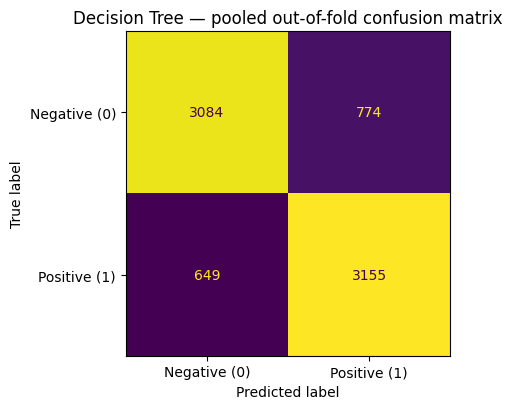

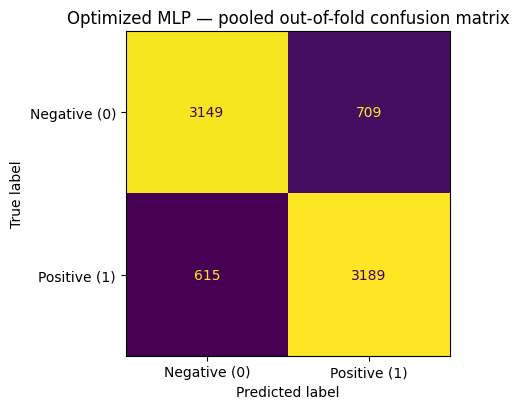

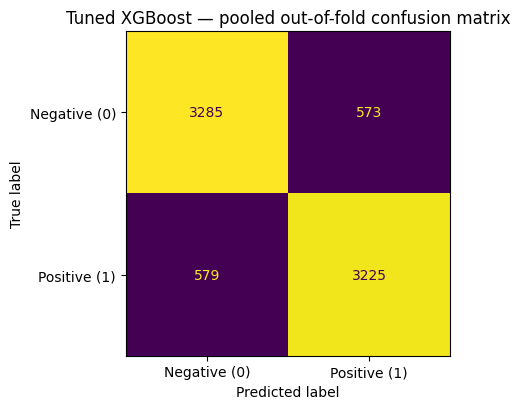

        model   TN  FP  FN   TP  total    FPR    FNR  validation_F1_mean  pooled_F1  validation_precision_mean  validation_recall_mean  validation_accuracy_mean  validation_ROC_AUC_mean
Decision Tree 3084 774 649 3155   7662 0.2006 0.1706              0.8159     0.8160                     0.8036                  0.8294                    0.8143                   0.8836
Optimized MLP 3149 709 615 3189   7662 0.1838 0.1617              0.8281     0.8281                     0.8198                  0.8383                    0.8272                   0.9110
Tuned XGBoost 3285 573 579 3225   7662 0.1485 0.1522              0.8484     0.8485                     0.8495                  0.8478                    0.8496                   0.9311


In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
for name in ['Decision Tree', 'Optimized MLP', 'Tuned XGBoost']:
    g=preds[preds.model==name]
    cm=confusion_matrix(g.actual,g.predicted,labels=[0,1])
    fig,ax=plt.subplots(figsize=(5.2,4.2))
    ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Negative (0)','Positive (1)']).plot(ax=ax, values_format='d', colorbar=False)
    ax.set_title(name+' — pooled out-of-fold confusion matrix')
    plt.tight_layout()
    plt.show()
print(pd.DataFrame(summary).round(4).to_string(index=False))

## 3. Where the models disagree


In [5]:
original_counts = wide[["both_wrong", "tree_only_wrong", "mlp_only_wrong"]].sum().astype(int)
print("Original Decision Tree / MLP overlap:")
print(original_counts.to_string())
print("\nOverlap involving XGBoost:")
print(wide[["all_three_wrong", "tree_xgboost_wrong", "mlp_xgboost_wrong", "xgboost_only_wrong", "xgboost_correct_others_wrong"]].sum().astype(int).to_string())
print("\nExamples all three models misclassified:")
cols = ["kepid", "kepoi_name", "actual", "Decision Tree", "Optimized MLP", "Tuned XGBoost", "koi_model_snr", "koi_depth", "koi_duration"]
print(wide.loc[wide["all_three_wrong"], cols].head(12).to_string(index=False))
print("\nExamples where XGBoost is correct but both other models are wrong:")
print(wide.loc[wide["xgboost_correct_others_wrong"], cols].head(12).to_string(index=False))

Original Decision Tree / MLP overlap:
both_wrong         835
tree_only_wrong    588
mlp_only_wrong     489

Overlap involving XGBoost:
all_three_wrong                 641
tree_xgboost_wrong              804
mlp_xgboost_wrong               817
xgboost_only_wrong              172
xgboost_correct_others_wrong    194

Examples all three models misclassified:
   kepid kepoi_name  actual Decision Tree Optimized MLP Tuned XGBoost  koi_model_snr  koi_depth  koi_duration
12459725  K00789.01       0            FP            FP            FP           11.2      459.9        2.5050
 4936180  K00820.01       1            FN            FN            FN          296.9     2450.6       35.5120
 5115978  K00823.01       1            FN            FN            FN           89.6     8098.0        1.8606
 3231341  K01102.03       1            FN            FN            FN           16.9      430.7        4.5290
11502218  K00970.01       1            FN            FN            FN           37.1      673

## 4. Error characteristics



        model error_type          feature  errors_n  correct_same_class_n  error_median  correct_median
Decision Tree         FP    koi_model_snr       774                  3084        13.100          63.700
Decision Tree         FP        koi_depth       774                  3084       263.300        1117.050
Decision Tree         FP     koi_duration       774                  3084         3.298           4.276
Decision Tree         FP       koi_period       774                  3084        13.715           3.844
Decision Tree         FP koi_num_transits       774                  3084       128.000         338.500
Decision Tree         FP koi_max_sngle_ev       774                  3084         4.614          13.069
Decision Tree         FP          koi_teq       774                  3084       783.000        1293.500
Decision Tree         FN    koi_model_snr       649                  3155        13.600          20.800
Decision Tree         FN        koi_depth       649             

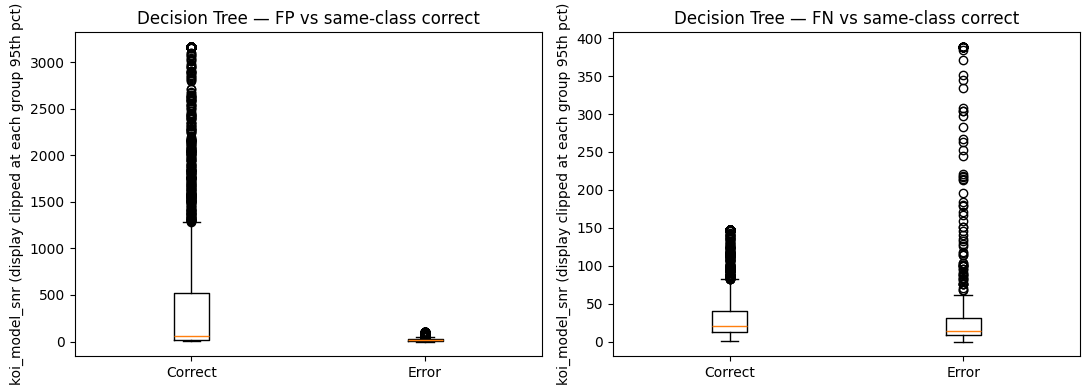

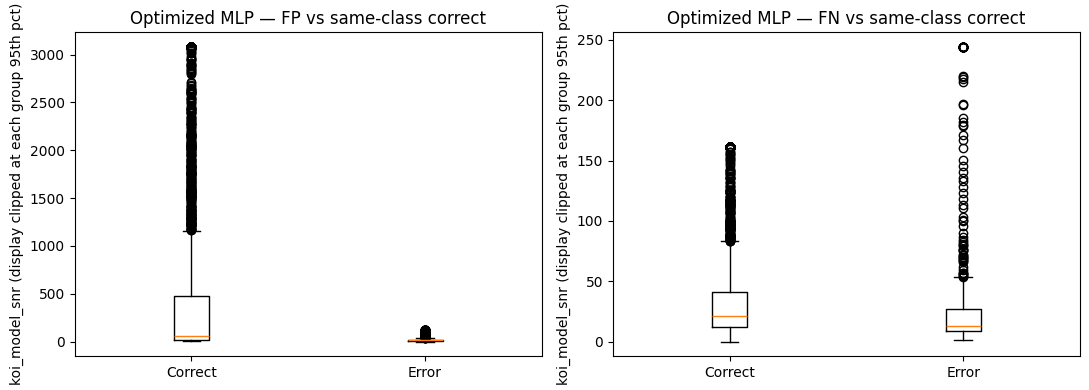

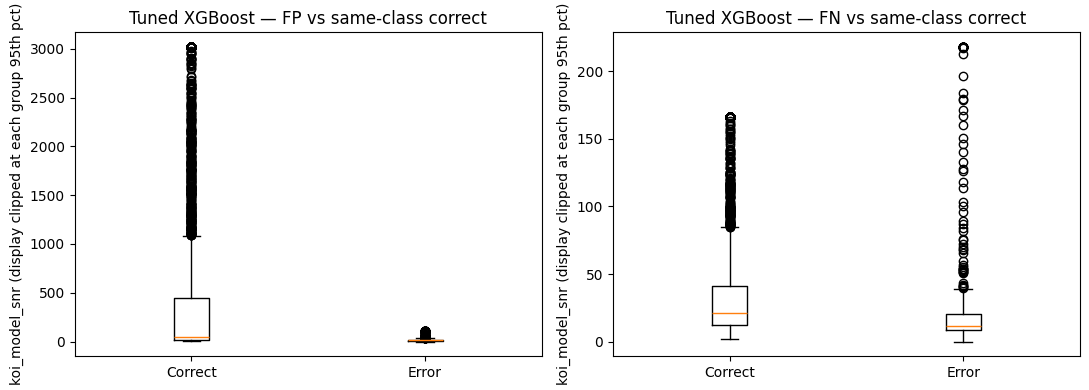

In [6]:
pat=pd.DataFrame(patterns)
print(pat.round(3).to_string(index=False))
for name in ['Decision Tree', 'Optimized MLP', 'Tuned XGBoost']:
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    g=preds[preds.model==name].set_index('row_index').join(X)
    for ax,actual,etype in zip(axes,[0,1],['FP','FN']):
        a=g.loc[(g.actual==actual)&(g.error_type=='correct'),'koi_model_snr'].dropna()
        b=g.loc[(g.actual==actual)&(g.error_type==etype),'koi_model_snr'].dropna()
        ax.boxplot([a.clip(upper=a.quantile(.95)),b.clip(upper=b.quantile(.95))],tick_labels=['Correct','Error'])
        ax.set_title(name+' — '+etype+' vs same-class correct')
        ax.set_ylabel('koi_model_snr (display clipped at each group 95th pct)')
    plt.tight_layout();plt.show()

## 5. Compare false-positive and false-negative counts across three models

All counts below use pooled held-out predictions, one per observation and model. A lower number of false positives may come with more false negatives, so examine both types of error together.

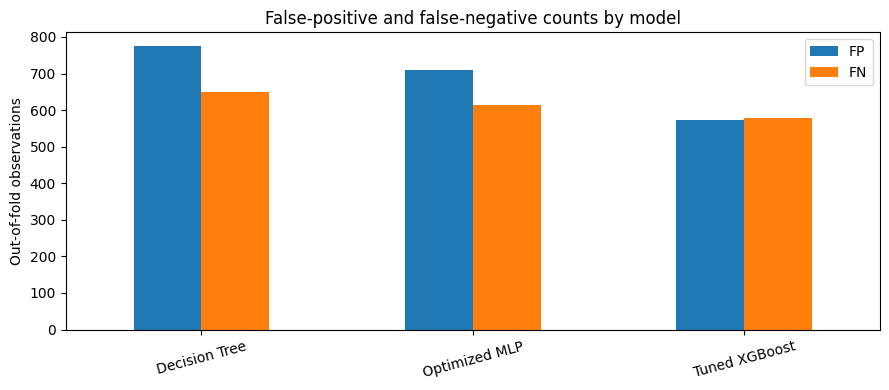

,model,FP,FN,validation_F1_mean,validation_ROC_AUC_mean
0,Decision Tree,774,649,0.8159,0.8836
1,Optimized MLP,709,615,0.8281,0.9110
2,Tuned XGBoost,573,579,0.8484,0.9311


In [7]:
error_counts = summary_df.set_index("model")[["FP", "FN"]]
ax = error_counts.plot(kind="bar", figsize=(9, 4), rot=15)
ax.set_title("False-positive and false-negative counts by model")
ax.set_ylabel("Out-of-fold observations")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

display(summary_df[["model", "FP", "FN", "validation_F1_mean", "validation_ROC_AUC_mean"]].round(4))

## WEAK SIGNALS

SNR cutoff: 12.0
        model  weak_signal_cases  actual_positives  false_negatives  missed_positive_rate
Decision Tree               1847               999              248              0.248248
Optimized MLP               1847               999              241              0.241241
Tuned XGBoost               1847               999              269              0.269269


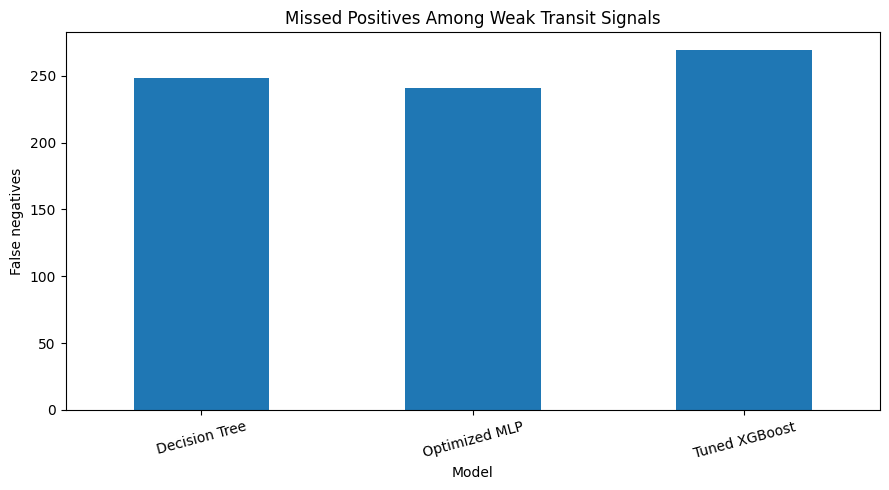

In [10]:

import pandas as pd
import matplotlib.pyplot as plt

snr_cutoff = X["koi_model_snr"].quantile(0.25)

weak_indices = X.index[
    X["koi_model_snr"] <= snr_cutoff
]

weak = preds[
    preds["row_index"].isin(weak_indices)
].copy()

results = []

for name, g in weak.groupby("model"):
    positives = g[g["actual"] == 1]
    false_negatives = positives[
        positives["predicted"] == 0
    ]

    results.append({
        "model": name,
        "weak_signal_cases": len(g),
        "actual_positives": len(positives),
        "false_negatives": len(false_negatives),
        "missed_positive_rate": (
            len(false_negatives) / len(positives)
            if len(positives) else 0
        )
    })

weak_summary = pd.DataFrame(results)

print("SNR cutoff:", round(snr_cutoff, 3))
print(weak_summary.to_string(index=False))

weak_summary.to_csv(
    "kepler_weak_signal_errors.csv",
    index=False
)

ax = weak_summary.set_index("model")[
    "false_negatives"
].plot(kind="bar", figsize=(9, 5))

ax.set_title("Missed Positives Among Weak Transit Signals")
ax.set_ylabel("False negatives")
ax.set_xlabel("Model")
ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()
